# Experiment analysis

Reads every run in `runs/` and compares the algorithms.

Run folders are `runs/<method>/seed<N>_<timestamp>/`. Each one holds `config.yaml`,
`history.csv` (one row per epoch), `metrics.json` (final numbers) and `predictions_<split>.csv`.

The notebook works with whatever is there, so it is usable after the first baseline run and
again after the full grid. Figures are saved to `reports/experiments/`.

**The three splits mean different things:**

| Split | Question it answers |
|---|---|
| `source_val` | did the model learn the task at all (sanity, not a result) |
| `target_test` | did adaptation help on the domain it adapted to (**main result**) |
| `test` | does it transfer to a domain never seen, not even unlabelled |

## 1. Settings and loading

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

RUNS_DIR = Path("../runs")
OUT_DIR = Path("../reports/experiments")
OUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
warnings.filterwarnings("ignore", category=FutureWarning)

CLASSES = ["no-damage", "minor-damage", "major-damage", "destroyed"]
SPLITS = ["source_val", "target_test", "test"]
SPLIT_LABEL = {"source_val": "source_val\n(us-central)",
               "target_test": "target_test\n(us-south)",
               "test": "test\n(caribbean)"}
# one colour per method, used everywhere
COLOR = {"baseline": "#4C72B0", "bn_only": "#937860", "coral": "#DD8452",
         "dann": "#55A868", "oracle": "#8172B3"}
# every table below reindexes on this list, so a method missing here is silently dropped
METHOD_ORDER = ["baseline", "bn_only", "coral", "dann", "oracle"]


def save_fig(name):
    plt.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def load_runs(runs_dir=RUNS_DIR):
    """Every run folder, finished or not."""
    runs = []
    for d in sorted(p for p in runs_dir.glob("*/*") if p.is_dir()):
        hist = pd.read_csv(d / "history.csv") if (d / "history.csv").exists() else None
        if hist is None or hist.empty:
            continue                                    # nothing logged yet
        cfg = yaml.safe_load((d / "config.yaml").read_text()) if (d / "config.yaml").exists() else {}
        met = json.loads((d / "metrics.json").read_text()) if (d / "metrics.json").exists() else None
        runs.append({
            "method": cfg.get("method", {}).get("name", d.parent.name),
            "seed": cfg.get("run", {}).get("seed"),
            "name": d.name,
            "path": d,
            "epochs_planned": cfg.get("optim", {}).get("epochs"),
            "finished": met is not None,
            "config": cfg,
            "history": hist,
            "metrics": met,
        })
    return runs


runs = load_runs()
if not runs:
    raise SystemExit(f"no runs found in {RUNS_DIR.resolve()}")

overview = pd.DataFrame([{
    "method": r["method"], "seed": r["seed"], "run": r["name"],
    "epochs_done": len(r["history"]), "epochs_planned": r["epochs_planned"],
    "finished": r["finished"],
    "best_source_val": r["history"]["source_val/macro_f1"].max().round(4),
} for r in runs])
print(f"{len(runs)} run(s) in {RUNS_DIR.resolve()}")
display(overview)

12 run(s) in /Users/_nltdzdbh_/Desktop/Desktop-icloud/McGill/Fall2026/ECSE552/final_project/Satellite-Disaster-Assessment-with-Domain-Adaptation/runs


,method,seed,run,epochs_done,epochs_planned,finished,best_source_val
0,baseline,14,seed14_20261122-052243,25,25,True,0.7129
1,baseline,1,seed1_20261122-024216,25,25,True,0.7072
2,baseline,3,seed3_20261122-000109,25,25,True,0.7147
3,bn_only,14,seed14_20261122-055030,25,25,True,0.7239
4,bn_only,1,seed1_20261122-030952,25,25,True,0.7188
5,bn_only,3,seed3_20261122-002908,25,25,True,0.7195
6,coral,14,seed14_20261122-062509,25,25,True,0.7158
7,coral,1,seed1_20261122-034429,25,25,True,0.7199
8,coral,3,seed3_20261122-010355,25,25,True,0.7141
9,dann,14,seed14_20261122-071409,25,25,True,0.7162


## 2. How many epochs do we need?

The curve of `source_val` macro-F1 against epoch. Use it to set `optim.epochs` for the whole
grid, then keep that number the same for every method so the comparison stays fair.

The dashed line marks the **plateau epoch**: the first epoch within 1 % of the best score. If
that happens well before the end, the remaining epochs are being spent for nothing.

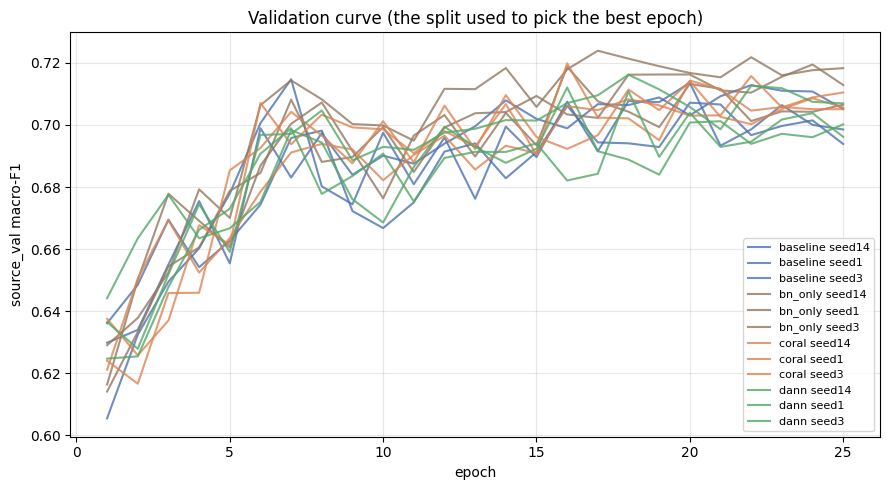

,method,seed,epochs,best_epoch,best_macro_f1,plateau_epoch(1%),gain_after_plateau
0,baseline,14,25,22,0.7129,14,0.0049
1,baseline,1,25,20,0.7072,16,0.0010
2,baseline,3,25,7,0.7147,7,0.0000
3,bn_only,14,25,17,0.7239,14,0.0056
4,bn_only,1,25,16,0.7188,16,0.0000
5,bn_only,3,25,24,0.7195,18,0.0033
6,coral,14,25,22,0.7158,22,0.0000
7,coral,1,25,16,0.7199,16,0.0000
8,coral,3,25,20,0.7141,14,0.0045
9,dann,14,25,18,0.7162,17,0.0066


Suggested optim.epochs: about 25 (latest plateau across runs, plus a small margin)


In [2]:
def plateau_epoch(series, tol=0.01):
    """First epoch within tol of the best value."""
    best = series.max()
    reached = series[series >= best * (1 - tol)]
    return int(reached.index[0]) + 1 if len(reached) else None


fig, ax = plt.subplots(figsize=(9, 5))
rows = []
for r in runs:
    h, m = r["history"], r["method"]
    s = h["source_val/macro_f1"]
    ax.plot(h["epoch"] + 1, s, color=COLOR.get(m, "gray"), alpha=0.8,
            label=f"{m} seed{r['seed']}")
    best_ep = int(s.idxmax()) + 1
    plat = plateau_epoch(s)
    rows.append({"method": m, "seed": r["seed"], "epochs": len(h),
                 "best_epoch": best_ep, "best_macro_f1": round(s.max(), 4),
                 "plateau_epoch(1%)": plat,
                 "gain_after_plateau": round(s.max() - s.iloc[plat - 1], 4) if plat else None})

ax.set_xlabel("epoch")
ax.set_ylabel("source_val macro-F1")
ax.set_title("Validation curve (the split used to pick the best epoch)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
save_fig("val_curves")
plt.show()

budget = pd.DataFrame(rows)
display(budget)
if budget["plateau_epoch(1%)"].notna().any():
    print(f"Suggested optim.epochs: about {int(budget['plateau_epoch(1%)'].max()) + 3} "
          f"(latest plateau across runs, plus a small margin)")

## 3. Overfitting check

Read from the **losses**, not from accuracy. Validation loss turns up well before macro-F1
falls, because the model first becomes over-confident on examples it already gets wrong.

The train side is `cls_loss`, not `loss`: `loss = cls_loss + adaptation term`, so `loss` is
not comparable to the validation loss or across methods. `cls_loss` and `source_val/loss`
are the same weighted cross-entropy and can be read against each other directly.


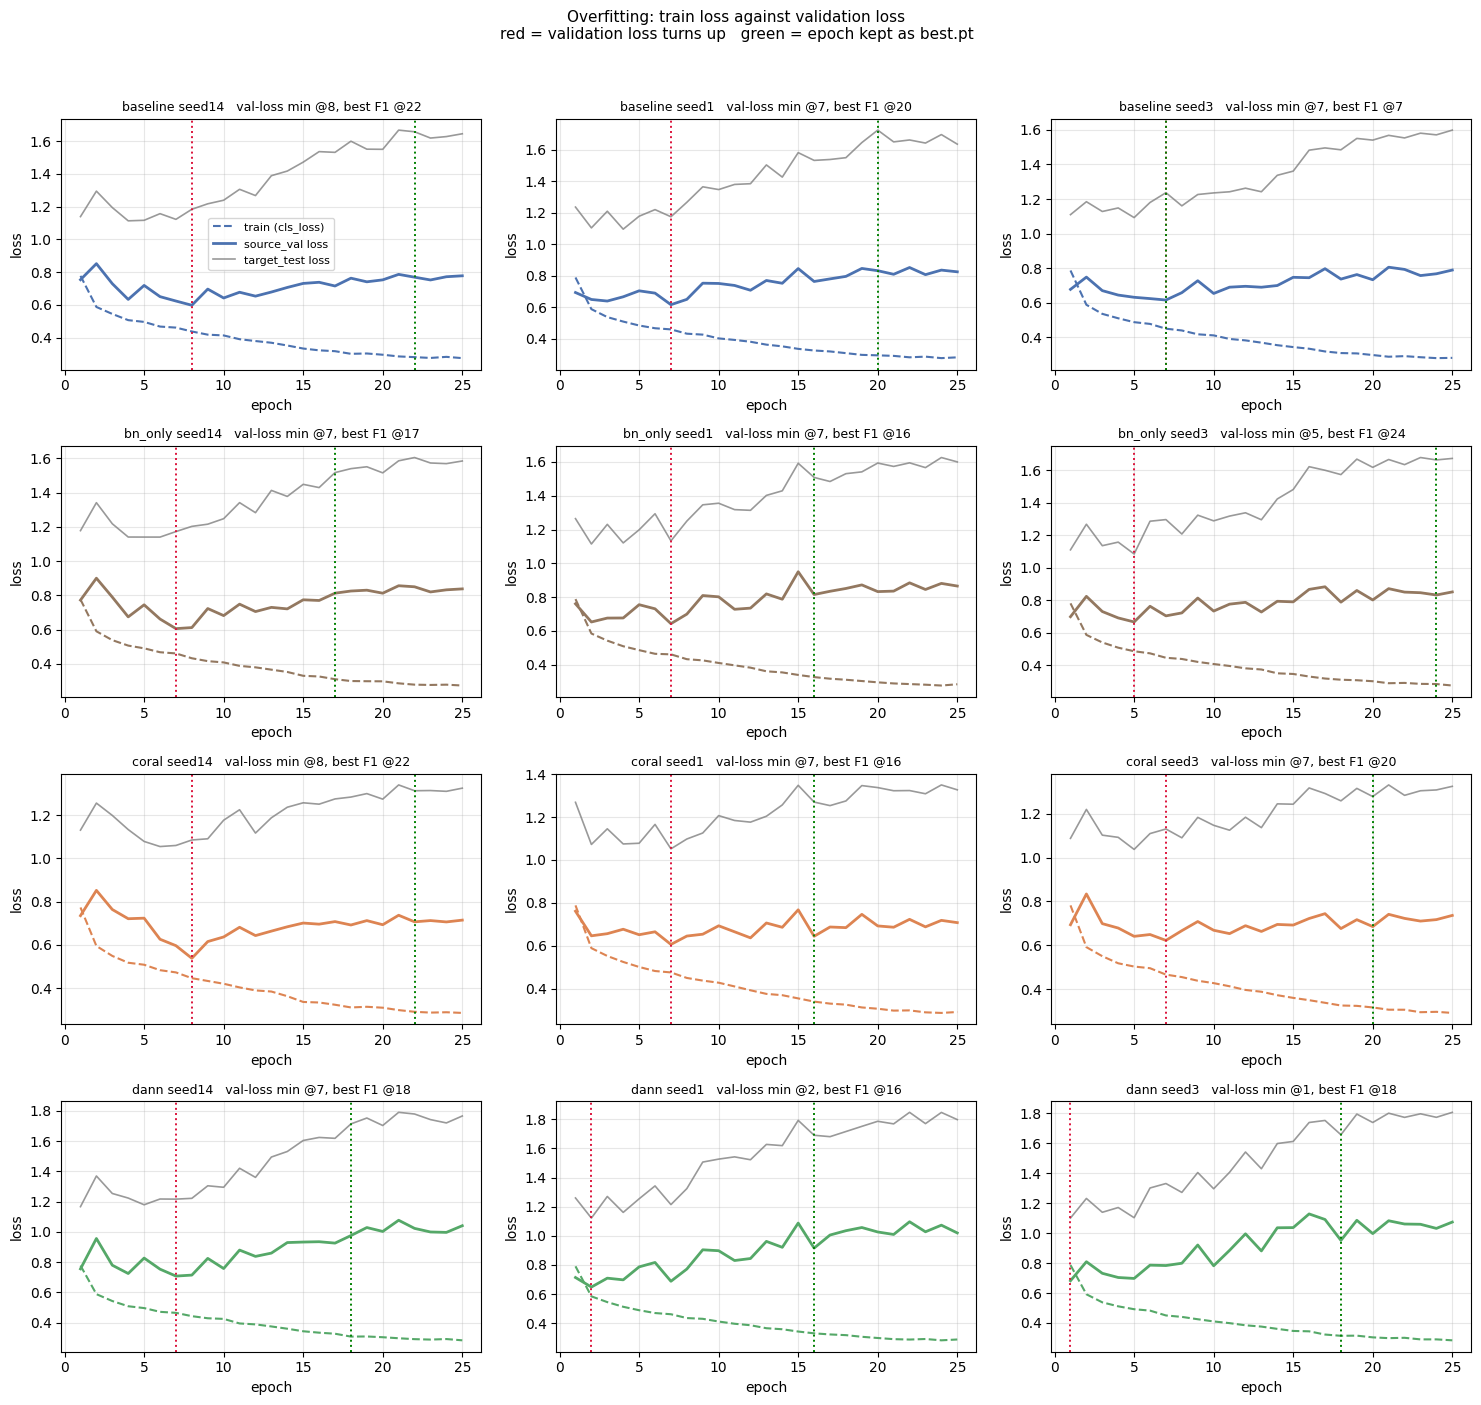

Validation loss turns up at epoch, versus the epoch actually kept

  method  seed  val_loss_min_epoch  best_f1_epoch  epochs_after_turn  train_cls_loss_end  val_loss_min  val_loss_end  val_loss_rise
baseline    14                   8             22                 14              0.2740        0.5970        0.7771         0.1801
baseline     1                   7             20                 13              0.2821        0.6166        0.8254         0.2088
baseline     3                   7              7                  0              0.2810        0.6157        0.7891         0.1734
 bn_only    14                   7             17                 10              0.2732        0.6054        0.8374         0.2320
 bn_only     1                   7             16                  9              0.2847        0.6433        0.8659         0.2226
 bn_only     3                   5             24                 19              0.2764        0.6677        0.8524         0.1847
   coral 

In [3]:
# Overfitting is read from the LOSSES, not from accuracy: validation loss turns upward well
# before macro-F1 starts falling, because the model first becomes over-confident on the
# examples it already gets wrong.
#
# Train side uses cls_loss, NOT loss. `loss` = cls_loss + the adaptation term, so it is not
# comparable to the validation loss or across methods. cls_loss and source_val/loss are the
# same weighted cross-entropy, so they can be read against each other directly.
n = len(runs)
cols = min(3, n)
rows_n = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(5 * cols, 3.5 * rows_n), squeeze=False)
summary = []

for i, r in enumerate(runs):
    ax = axes[i // cols][i % cols]
    h, m = r["history"], r["method"]
    ep = h["epoch"] + 1
    c = COLOR.get(m, "black")

    ax.plot(ep, h["cls_loss"], color=c, ls="--", label="train (cls_loss)")
    ax.plot(ep, h["source_val/loss"], color=c, lw=2, label="source_val loss")
    if "target_test/loss" in h.columns:
        ax.plot(ep, h["target_test/loss"], color="gray", lw=1.2, alpha=.8, label="target_test loss")

    turn = int(h["source_val/loss"].idxmin()) + 1               # where val loss bottoms out
    best = int(h["source_val/macro_f1"].idxmax()) + 1           # the epoch actually kept
    ax.axvline(turn, color="crimson", ls=":", lw=1.4)
    ax.axvline(best, color="green", ls=":", lw=1.4)
    ax.set_title(f"{m} seed{r['seed']}   val-loss min @{turn}, best F1 @{best}", fontsize=9)
    ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.grid(alpha=.3)
    if i == 0: ax.legend(fontsize=8)

    summary.append({"method": m, "seed": r["seed"],
                    "val_loss_min_epoch": turn, "best_f1_epoch": best,
                    "epochs_after_turn": best - turn,
                    "train_cls_loss_end": round(h["cls_loss"].iloc[-1], 4),
                    "val_loss_min": round(h["source_val/loss"].min(), 4),
                    "val_loss_end": round(h["source_val/loss"].iloc[-1], 4)})

for j in range(n, rows_n * cols): axes[j // cols][j % cols].axis("off")
fig.suptitle("Overfitting: train loss against validation loss\n"
             "red = validation loss turns up   green = epoch kept as best.pt", y=1.0, fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.98]); save_fig("overfitting_loss"); plt.show()

s = pd.DataFrame(summary)
s["val_loss_rise"] = (s["val_loss_end"] - s["val_loss_min"]).round(4)
print("Validation loss turns up at epoch, versus the epoch actually kept\n")
print(s.to_string(index=False))
print(f"\nmedian turn epoch {int(s['val_loss_min_epoch'].median())}, "
      f"median kept epoch {int(s['best_f1_epoch'].median())}")
print("A kept epoch well after the turn means macro-F1 kept improving while the loss got worse:")
print("the model is growing over-confident but still ranking the classes better.")


## 4. Loss curves

`cls_loss` is the weighted cross-entropy, present in every method. `extra_loss` is the CORAL or
domain term and appears only for those runs.

**For CORAL:** if `extra_loss` is orders of magnitude smaller than `cls_loss`, the alignment term
is doing nothing and `method.lambda_weight` should go up. The Deep CORAL paper sets lambda so the
two end up comparable.

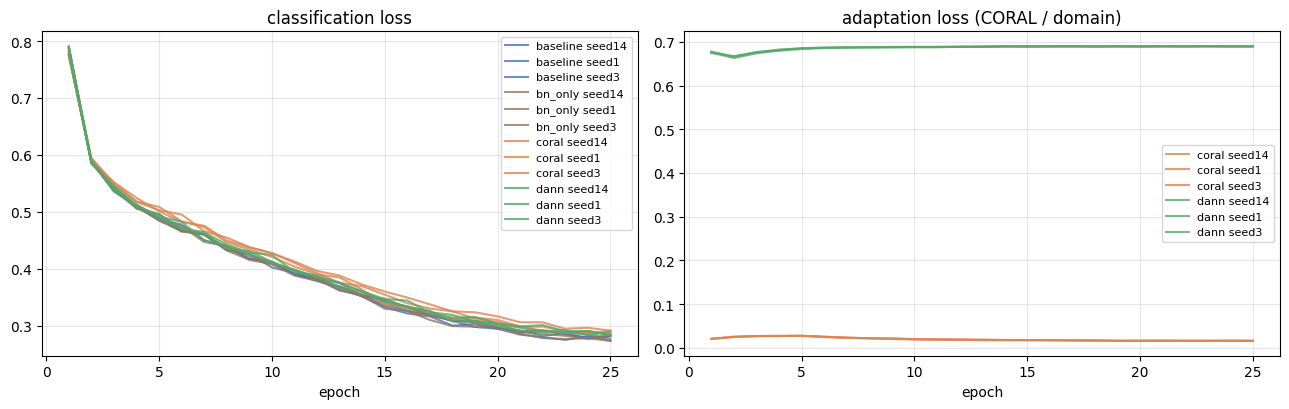

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for r in runs:
    h, m = r["history"], r["method"]
    axes[0].plot(h["epoch"] + 1, h["cls_loss"], color=COLOR.get(m, "gray"),
                 alpha=0.8, label=f"{m} seed{r['seed']}")
    if "extra_loss" in h.columns and h["extra_loss"].abs().sum() > 0:
        axes[1].plot(h["epoch"] + 1, h["extra_loss"], color=COLOR.get(m, "gray"),
                     alpha=0.8, label=f"{m} seed{r['seed']}")
axes[0].set_title("classification loss")
axes[1].set_title("adaptation loss (CORAL / domain)")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
if not axes[1].lines:
    axes[1].text(0.5, 0.5, "no adaptation runs yet", ha="center", va="center",
                 transform=axes[1].transAxes, color="gray")
plt.tight_layout()
save_fig("loss_curves")
plt.show()

## 5. Domain-adaptation diagnostics

Only for CORAL and DANN.

- **lambda**: the adaptation weight. CORAL ramps it linearly over `method.ramp_epochs`; DANN uses
  `2/(1+exp(-gamma*p))-1`, which with gamma=10 is about 85 % complete a quarter of the way in.
- **domain accuracy** (DANN only): how well the discriminator separates source from target.
  **Near 0.5 is the goal** - the features look the same to it. Stuck near 1.0 means the
  discriminator is winning and no adaptation is happening. Dropping to 0.5 immediately while the
  classification loss stops improving means it is winning too hard; lower `method.gamma`.

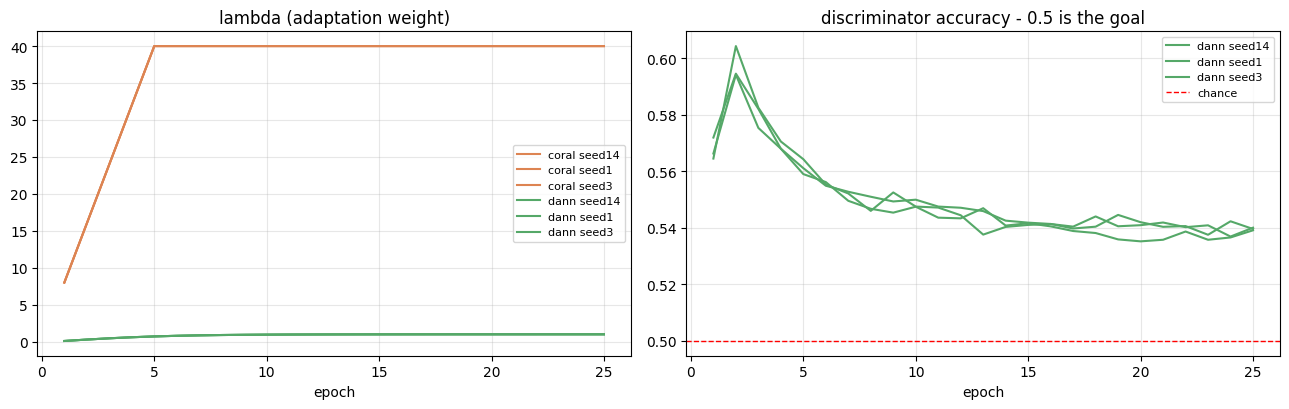

In [6]:
da_runs = [r for r in runs if r["method"] in ("coral", "dann")]
if not da_runs:
    print("No CORAL or DANN runs yet. Come back after running them.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for r in da_runs:
        h, m = r["history"], r["method"]
        if "lambda" in h.columns:
            axes[0].plot(h["epoch"] + 1, h["lambda"], color=COLOR.get(m, "gray"),
                         label=f"{m} seed{r['seed']}")
        if "domain_acc" in h.columns:
            axes[1].plot(h["epoch"] + 1, h["domain_acc"], color=COLOR.get(m, "gray"),
                         label=f"{m} seed{r['seed']}")
    axes[0].set_title("lambda (adaptation weight)")
    axes[1].set_title("discriminator accuracy - 0.5 is the goal")
    axes[1].axhline(0.5, color="red", ls="--", lw=1, label="chance")
    for ax in axes:
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    plt.tight_layout()
    save_fig("da_diagnostics")
    plt.show()

## 6. Results table

Mean ± standard deviation across seeds, from the best checkpoint of each run.

Report this table. With 3 seeds the standard deviation is rough, but it is enough to stop you
reading meaning into a one-point difference. Paper 2's own xBD numbers carry about ±0.02.

In [7]:
finished = [r for r in runs if r["finished"]]
if not finished:
    print("No finished run yet (metrics.json missing).")
else:
    long = pd.DataFrame([
        {"method": r["method"], "seed": r["seed"], "split": split, **r["metrics"]["splits"][split]}
        for r in finished for split in SPLITS if split in r["metrics"]["splits"]
    ])

    def mean_std(df, col):
        g = df.groupby(["method", "split"])[col].agg(["mean", "std", "count"])
        g["text"] = g.apply(
            lambda x: f"{x['mean']:.4f}" + (f" ± {x['std']:.4f}" if x["count"] > 1 else " (1 run)"),
            axis=1)
        return g

    main = mean_std(long, "macro_f1")["text"].unstack("split")
    main = main.reindex(index=[m for m in METHOD_ORDER if m in main.index],
                        columns=[s for s in SPLITS if s in main.columns])
    print("macro-F1, mean ± std over seeds")
    display(main)

    print("accuracy")
    display(mean_std(long, "accuracy")["text"].unstack("split")
            .reindex(index=[m for m in METHOD_ORDER if m in long["method"].unique()],
                     columns=[s for s in SPLITS if s in long["split"].unique()]))

    long.to_csv(OUT_DIR / "all_results_long.csv", index=False)
    print(f"\nraw numbers saved to {OUT_DIR / 'all_results_long.csv'}")

macro-F1, mean ± std over seeds


split,source_val,target_test,test
method,,,
baseline,0.7116 ± 0.0039,0.5335 ± 0.0035,0.2168 ± 0.0045
bn_only,0.7207 ± 0.0028,0.5350 ± 0.0024,0.2356 ± 0.0080
coral,0.7166 ± 0.0030,0.5317 ± 0.0030,0.2235 ± 0.0105
dann,0.7130 ± 0.0028,0.5320 ± 0.0042,0.2274 ± 0.0084


accuracy


split,source_val,target_test,test
method,,,
baseline,0.8758 ± 0.0017,0.6715 ± 0.0043,0.2477 ± 0.0072
bn_only,0.8854 ± 0.0021,0.6596 ± 0.0036,0.2576 ± 0.0087
coral,0.8831 ± 0.0009,0.6658 ± 0.0061,0.2439 ± 0.0077
dann,0.8790 ± 0.0018,0.6644 ± 0.0042,0.2459 ± 0.0064



raw numbers saved to ../reports/experiments/all_results_long.csv


## 7. The domain gap

The whole point of the project in one figure: how much macro-F1 is lost when the domain changes,
and whether adaptation recovers any of it.

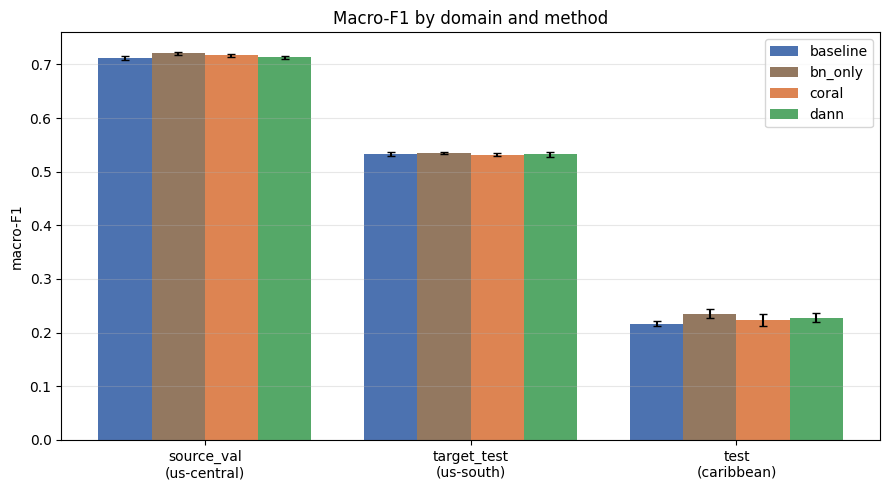

Drop relative to source_val (negative = worse on the new domain)


absolute             percent      
split    target_test    test target_test  test
method                                        
baseline     -0.1781 -0.4948       -25.0 -69.5
bn_only      -0.1857 -0.4852       -25.8 -67.3
coral        -0.1849 -0.4931       -25.8 -68.8
dann         -0.1810 -0.4856       -25.4 -68.1

In [8]:
if finished:
    piv = long.pivot_table(index="method", columns="split", values="macro_f1", aggfunc="mean")
    piv = piv.reindex(index=[m for m in METHOD_ORDER if m in piv.index],
                      columns=[s for s in SPLITS if s in piv.columns])
    err = long.pivot_table(index="method", columns="split", values="macro_f1",
                           aggfunc="std").reindex_like(piv).fillna(0)

    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(piv.columns))
    width = 0.8 / max(1, len(piv))
    for i, method in enumerate(piv.index):
        ax.bar(x + i * width, piv.loc[method], width, yerr=err.loc[method], capsize=3,
               label=method, color=COLOR.get(method, "gray"))
    ax.set_xticks(x + width * (len(piv) - 1) / 2)
    ax.set_xticklabels([SPLIT_LABEL.get(c, c) for c in piv.columns])
    ax.set_ylabel("macro-F1")
    ax.set_title("Macro-F1 by domain and method")
    ax.grid(alpha=0.3, axis="y")
    ax.legend()
    plt.tight_layout()
    save_fig("domain_gap")
    plt.show()

    print("Drop relative to source_val (negative = worse on the new domain)")
    gap = piv.sub(piv["source_val"], axis=0).drop(columns="source_val", errors="ignore")
    rel = (100 * gap.div(piv["source_val"], axis=0)).round(1)
    display(pd.concat({"absolute": gap.round(4), "percent": rel}, axis=1))

## 8. Per-class F1

Macro-F1 averages these four numbers, so this is where you see *which* class a method helps.
`major-damage` is the thinnest class in the source (3.9 %), and `minor-damage` is the one that
dominates the caribbean test set (54.5 %) while being rare in the source (8.3 %).

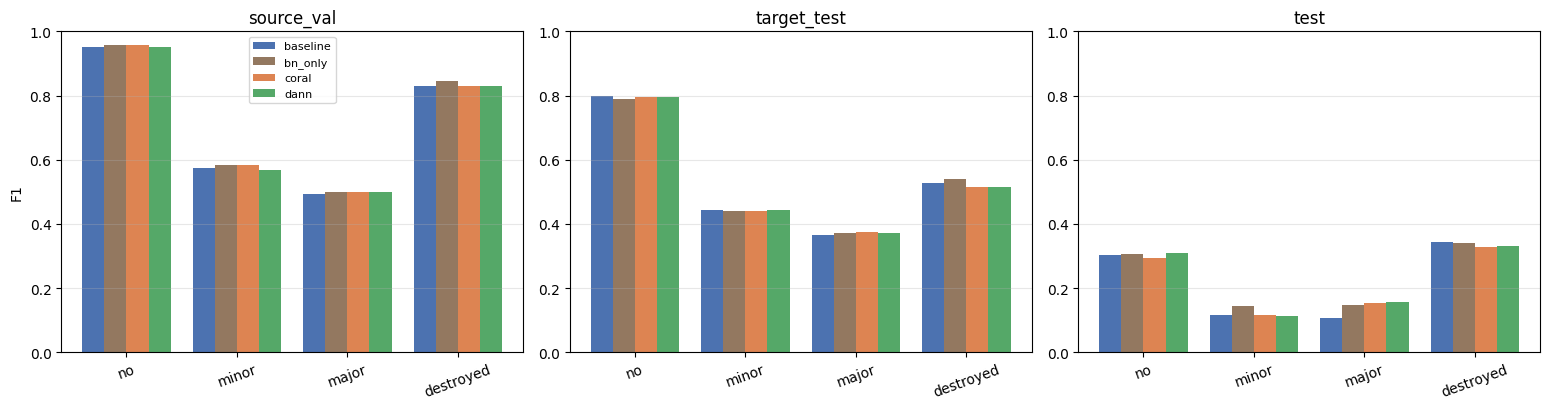

In [9]:
if finished:
    fig, axes = plt.subplots(1, len(SPLITS), figsize=(5.2 * len(SPLITS), 4.2), squeeze=False)
    for k, split in enumerate(SPLITS):
        ax = axes[0][k]
        sub = long[long["split"] == split]
        if sub.empty:
            ax.axis("off")
            continue
        per_class = sub.groupby("method")[[f"f1/{c}" for c in CLASSES]].mean()
        per_class = per_class.reindex([m for m in METHOD_ORDER if m in per_class.index])
        x = np.arange(len(CLASSES))
        width = 0.8 / max(1, len(per_class))
        for i, method in enumerate(per_class.index):
            ax.bar(x + i * width, per_class.loc[method], width, label=method,
                   color=COLOR.get(method, "gray"))
        ax.set_xticks(x + width * (len(per_class) - 1) / 2)
        ax.set_xticklabels([c.replace("-damage", "") for c in CLASSES], rotation=20)
        ax.set_title(split)
        ax.set_ylim(0, 1)
        ax.grid(alpha=0.3, axis="y")
        if k == 0:
            ax.set_ylabel("F1")
            ax.legend(fontsize=8)
    plt.tight_layout()
    save_fig("per_class_f1")
    plt.show()

## 9. Confusion matrices

Rows are the truth, columns the prediction, normalised per row so each row sums to 1. The
diagonal is recall.

This is where the failure mode shows. A column that is dark all the way down means the model
dumps everything into that class.

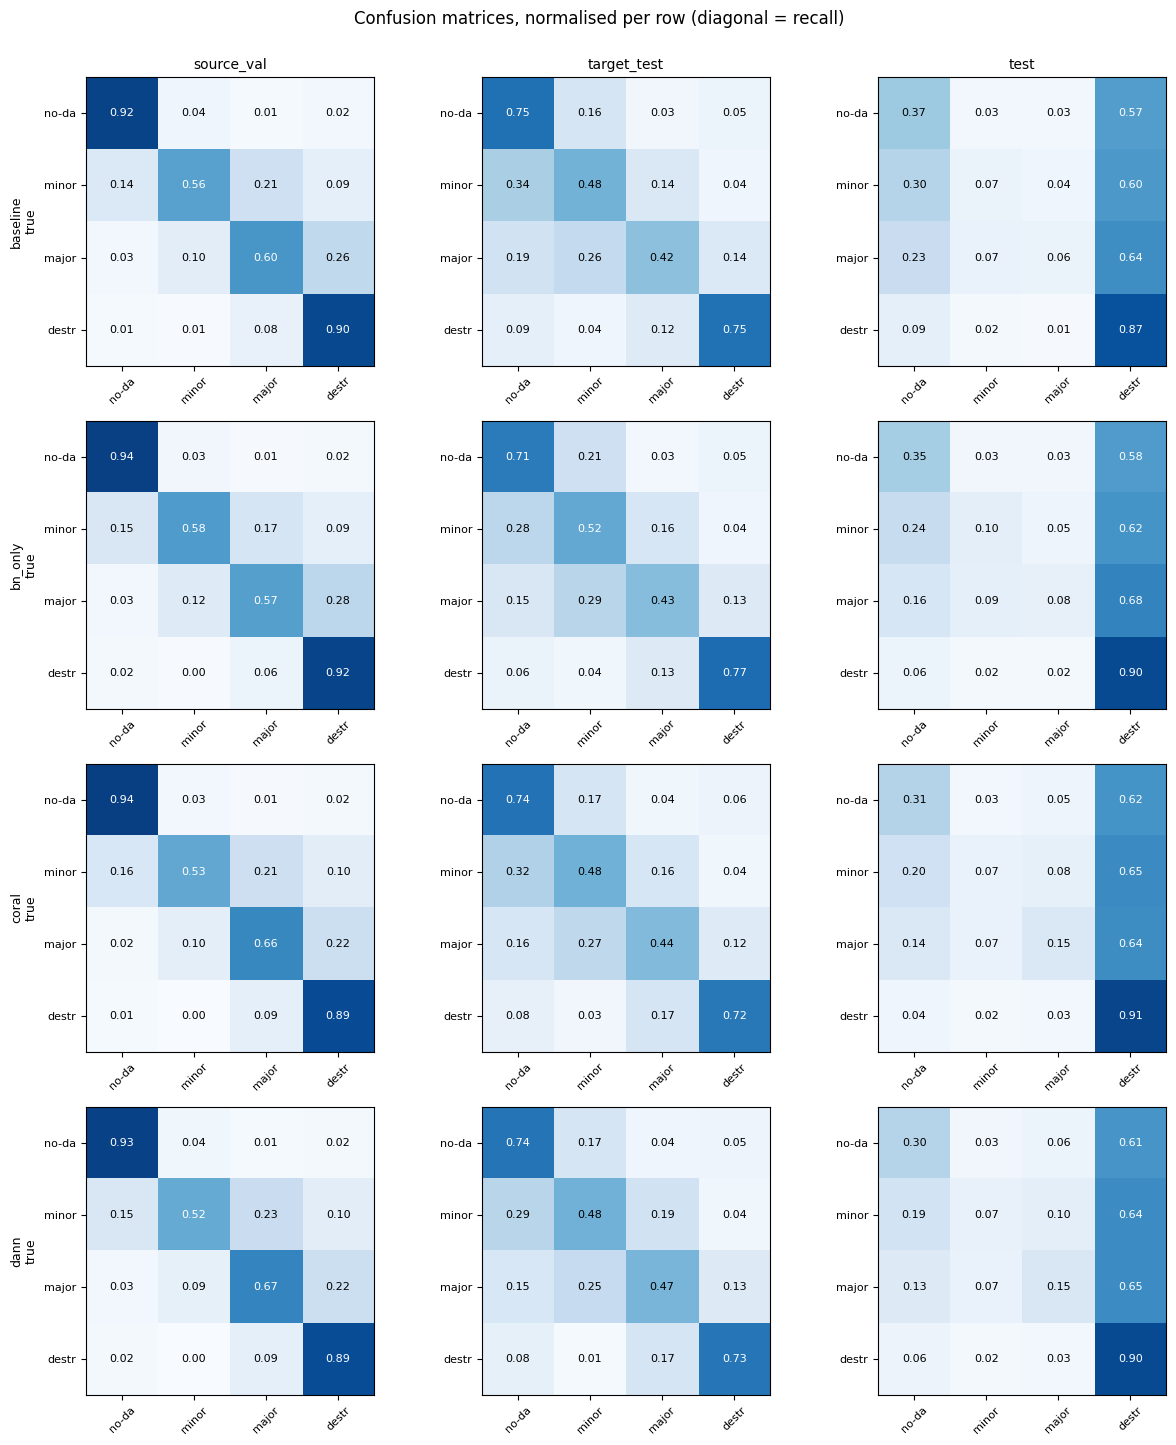

In [10]:
def load_predictions(run, split):
    f = run["path"] / f"predictions_{split}.csv"
    return pd.read_csv(f) if f.exists() else None


def confusion_norm(df, n=4):
    cm = np.zeros((n, n))
    for t, p in zip(df["true_label"], df["pred_label"]):
        cm[int(t), int(p)] += 1
    totals = cm.sum(axis=1, keepdims=True)
    return cm, np.divide(cm, totals, out=np.zeros_like(cm), where=totals > 0)


# one run per method: the best seed on target_test, else the first one
chosen = {}
for r in finished:
    key = r["method"]
    score = r["metrics"]["splits"].get("target_test", {}).get("macro_f1", -1)
    if key not in chosen or score > chosen[key][1]:
        chosen[key] = (r, score)
chosen = {k: v[0] for k, v in chosen.items()}

methods = [m for m in METHOD_ORDER if m in chosen]
if methods:
    fig, axes = plt.subplots(len(methods), len(SPLITS),
                             figsize=(4.2 * len(SPLITS), 3.6 * len(methods)), squeeze=False)
    for i, method in enumerate(methods):
        for j, split in enumerate(SPLITS):
            ax = axes[i][j]
            pred = load_predictions(chosen[method], split)
            if pred is None:
                ax.axis("off")
                continue
            _, norm = confusion_norm(pred)
            ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
            for a in range(4):
                for b in range(4):
                    ax.text(b, a, f"{norm[a, b]:.2f}", ha="center", va="center", fontsize=8,
                            color="white" if norm[a, b] > 0.5 else "black")
            ax.set_xticks(range(4))
            ax.set_yticks(range(4))
            ax.set_xticklabels([c[:5] for c in CLASSES], rotation=45, fontsize=8)
            ax.set_yticklabels([c[:5] for c in CLASSES], fontsize=8)
            if i == 0:
                ax.set_title(split, fontsize=10)
            if j == 0:
                ax.set_ylabel(f"{method}\ntrue", fontsize=9)
    fig.suptitle("Confusion matrices, normalised per row (diagonal = recall)", y=1.0)
    plt.tight_layout()
    save_fig("confusion_matrices")
    plt.show()

## 10. What the model predicts, versus what is there

A model can look reasonable on accuracy while predicting one class far too often. This compares
the predicted class distribution with the true one for each split.

A large gap here is the signature of **label shift**: the source and target have different class
proportions, and the model carries the source proportions with it.

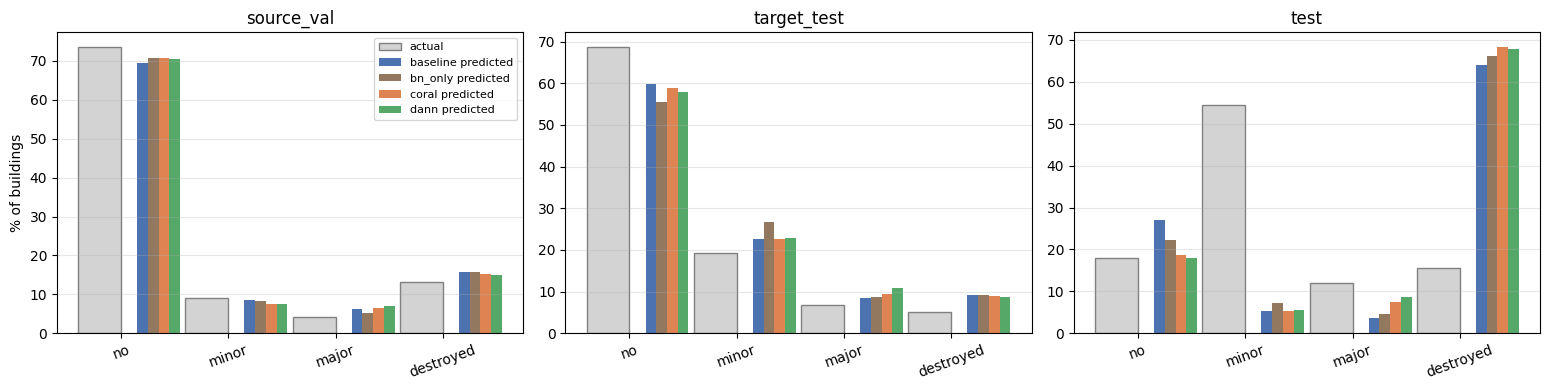

method                    baseline  bn_only  coral  dann
split       class                                       
source_val  destroyed         15.7     15.8   15.4  14.9
            major-damage       6.2      5.3    6.5   6.9
            minor-damage       8.6      8.3    7.4   7.6
            no-damage         69.5     70.6   70.7  70.5
target_test destroyed          9.2      9.1    9.1   8.6
            major-damage       8.4      8.7    9.4  10.8
            minor-damage      22.5     26.7   22.7  22.8
            no-damage         59.9     55.5   58.8  57.8
test        destroyed         64.0     66.1   68.4  67.8
            major-damage       3.6      4.6    7.6   8.6
            minor-damage       5.3      7.2    5.3   5.6
            no-damage         27.1     22.2   18.8  18.0

In [11]:
if methods:
    rows = []
    for method in methods:
        for split in SPLITS:
            pred = load_predictions(chosen[method], split)
            if pred is None:
                continue
            for c, name in enumerate(CLASSES):
                rows.append({"method": method, "split": split, "class": name,
                             "true %": 100 * (pred["true_label"] == c).mean(),
                             "pred %": 100 * (pred["pred_label"] == c).mean()})
    dist = pd.DataFrame(rows)

    fig, axes = plt.subplots(1, len(SPLITS), figsize=(5.2 * len(SPLITS), 4), squeeze=False)
    for k, split in enumerate(SPLITS):
        ax = axes[0][k]
        sub = dist[dist["split"] == split]
        if sub.empty:
            ax.axis("off")
            continue
        x = np.arange(len(CLASSES))
        truth = sub.groupby("class")["true %"].first().reindex(CLASSES)
        ax.bar(x - 0.2, truth, 0.4, label="actual", color="lightgray", edgecolor="gray")
        for i, method in enumerate(methods):
            p = sub[sub["method"] == method].set_index("class")["pred %"].reindex(CLASSES)
            ax.bar(x + 0.2 + i * 0.4 / max(1, len(methods)), p, 0.4 / max(1, len(methods)),
                   label=f"{method} predicted", color=COLOR.get(method, "gray"))
        ax.set_xticks(x)
        ax.set_xticklabels([c.replace("-damage", "") for c in CLASSES], rotation=20)
        ax.set_title(split)
        ax.grid(alpha=0.3, axis="y")
        if k == 0:
            ax.set_ylabel("% of buildings")
            ax.legend(fontsize=8)
    plt.tight_layout()
    save_fig("predicted_vs_actual_distribution")
    plt.show()
    display(dist.pivot_table(index=["split", "class"], columns="method",
                             values="pred %").round(1))

## 11. Do the methods fix the same buildings?

Compares every method against the baseline on the **same buildings**, so the question is not
just "is the score higher" but "which predictions actually changed".

- **fixed**: baseline wrong, this method right
- **broken**: baseline right, this method wrong
- **net**: fixed - broken

A method can raise macro-F1 while breaking almost as many buildings as it fixes. That is worth
knowing before claiming it works.

In [12]:
PRED_SPLIT = "test"        # change to "target_test" for the adapted domain


def predictions_wide(split, chosen_runs):
    '''One row per building, one column per method, for the methods that have this split.'''
    frames = {}
    for method, run in chosen_runs.items():
        p = load_predictions(run, split)
        if p is not None:
            frames[method] = p.set_index("building_uid")
    if not frames:
        return None
    first = next(iter(frames.values()))
    wide = pd.DataFrame({"true_label": first["true_label"]})
    for method, p in frames.items():
        wide[f"pred_{method}"] = p["pred_label"]
        wide[f"conf_{method}"] = p[[f"p_{c}" for c in CLASSES]].max(axis=1)
    return wide.dropna()


wide = predictions_wide(PRED_SPLIT, chosen)
if wide is None:
    print("no predictions found")
else:
    present = [m for m in METHOD_ORDER if f"pred_{m}" in wide.columns]
    print(f"split: {PRED_SPLIT}   buildings: {len(wide):,}   methods: {present}")

    rows = []
    for m in present:
        ok = wide[f"pred_{m}"] == wide["true_label"]
        row = {"method": m, "correct": int(ok.sum()), "accuracy": round(ok.mean(), 4)}
        if "baseline" in present and m != "baseline":
            base_ok = wide["pred_baseline"] == wide["true_label"]
            row["fixed"] = int((~base_ok & ok).sum())
            row["broken"] = int((base_ok & ~ok).sum())
            row["net"] = row["fixed"] - row["broken"]
        rows.append(row)
    display(pd.DataFrame(rows).set_index("method"))

    if len(present) > 1:
        wrong_all = np.logical_and.reduce([wide[f"pred_{m}"] != wide["true_label"] for m in present])
        right_all = np.logical_and.reduce([wide[f"pred_{m}"] == wide["true_label"] for m in present])
        print(f"\nevery method wrong : {wrong_all.sum():,} ({100 * wrong_all.mean():.1f} %)")
        print(f"every method right : {right_all.sum():,} ({100 * right_all.mean():.1f} %)")
        print("\nWhat every method gets wrong, by true class:")
        display(wide[wrong_all].groupby("true_label").size()
                .rename(index=dict(enumerate(CLASSES))).to_frame("buildings"))

split: test   buildings: 22,617   methods: ['baseline', 'bn_only', 'coral', 'dann']


,correct,accuracy,fixed,broken,net
method,,,,,
baseline,5575,0.2465,NaN,NaN,NaN
bn_only,5972,0.2640,1239.0,842.0,397.0
coral,5707,0.2523,1042.0,910.0,132.0
dann,5686,0.2514,1013.0,902.0,111.0



every method wrong : 14,926 (66.0 %)
every method right : 4,140 (18.3 %)

What every method gets wrong, by true class:


,buildings
true_label,
no-damage,2123
minor-damage,10473
major-damage,2154
destroyed,176


## 12. The same buildings, seen by every method

Picks a fixed set of buildings and shows the pre and post crop with what each method predicted.
Because the set is the same for all methods, you can read down a column and see whether a method
fixed that building or not. Green = correct, red = wrong.

`MODE` chooses what to look at:

| mode | buildings shown |
|---|---|
| `fixed` | baseline wrong, at least one other method right - **did adaptation help** |
| `broken` | baseline right, some method wrong - what adaptation cost |
| `all_wrong` | nobody gets them right - the genuinely hard cases |
| `baseline_errors` | a random sample of baseline mistakes |

mode 'fixed' on test: 8 of the matching buildings shown


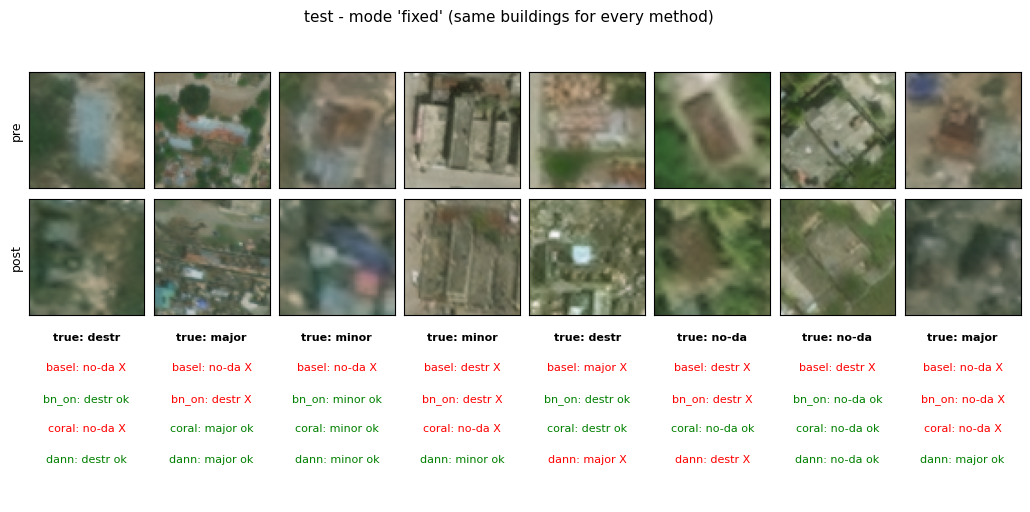

In [13]:
CROPS_DIR = Path("../crops/wind_64")
MODE = "fixed"
N_SHOW = 8
PICK_SEED = 0

manifest = pd.read_csv(CROPS_DIR / "manifest.csv").set_index("building_uid")
_arr_cache = {}


def crop_of(uid):
    '''(pre, post) crop of one building, from the memory-mapped arrays.'''
    row = manifest.loc[uid]
    out = []
    for when in ("pre", "post"):
        key = (row["split"], when)
        if key not in _arr_cache:
            _arr_cache[key] = np.load(CROPS_DIR / f"{row['split']}_{when}.npy", mmap_mode="r")
        out.append(np.array(_arr_cache[key][int(row["row"])]))
    return out


def pick(wide, methods, mode=MODE, n=N_SHOW, seed=PICK_SEED):
    ok = {m: wide[f"pred_{m}"] == wide["true_label"] for m in methods}
    others = [m for m in methods if m != "baseline"]
    if mode == "fixed" and others:
        sel = wide[~ok["baseline"] & np.logical_or.reduce([ok[m] for m in others])]
    elif mode == "broken" and others:
        sel = wide[ok["baseline"] & np.logical_or.reduce([~ok[m] for m in others])]
    elif mode == "all_wrong":
        sel = wide[np.logical_and.reduce([~ok[m] for m in methods])]
    else:
        sel = wide[~ok["baseline"]]
    if sel.empty:
        return sel
    return sel.sample(min(n, len(sel)), random_state=seed)


def show_cases(sel, methods, title="", mode=None):
    '''Pre and post crop per building, with every method's prediction underneath.'''
    if sel.empty:
        print("nothing matches this mode")
        return
    n = len(sel)
    fig = plt.figure(figsize=(1.6 * n, 5.6))
    gs = fig.add_gridspec(3, n, height_ratios=[1, 1, 1.5], hspace=0.05, wspace=0.08)
    for i, (uid, r) in enumerate(sel.iterrows()):
        pre, post = crop_of(uid)
        for j, img in ((0, pre), (1, post)):
            ax = fig.add_subplot(gs[j, i])
            ax.imshow(img)
            ax.set_xticks([]); ax.set_yticks([])
            if i == 0:
                ax.set_ylabel(["pre", "post"][j], fontsize=9)
        ax = fig.add_subplot(gs[2, i])
        ax.axis("off")
        true_name = CLASSES[int(r["true_label"])]
        ax.text(0.5, 0.95, f"true: {true_name[:5]}", ha="center", va="top",
                fontsize=8, fontweight="bold", transform=ax.transAxes)
        for k, m in enumerate(methods):
            pred = int(r[f"pred_{m}"])
            right = pred == int(r["true_label"])
            ax.text(0.5, 0.78 - 0.17 * k,
                    f"{m[:5]}: {CLASSES[pred][:5]} {'ok' if right else 'X'}",
                    ha="center", va="top", fontsize=8,
                    color="green" if right else "red", transform=ax.transAxes)
    fig.suptitle(title, y=0.99, fontsize=11)
    save_fig(f"cases_{mode or MODE}_{PRED_SPLIT}")
    plt.show()


if wide is not None:
    sel = pick(wide, present)
    print(f"mode '{MODE}' on {PRED_SPLIT}: {len(sel)} of the matching buildings shown")
    show_cases(sel, present, mode=MODE,
               title=f"{PRED_SPLIT} - mode '{MODE}' (same buildings for every method)")

Change `MODE` and re-run the two cells above to look at the other groups. `all_wrong` is usually
the most informative: if those crops are unreadable even to you, the ceiling is the data, not the
method.

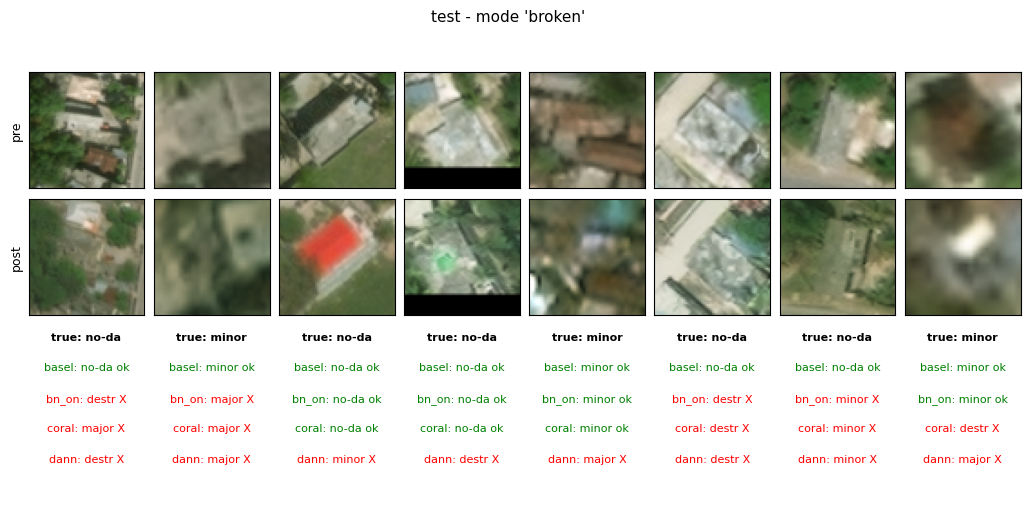

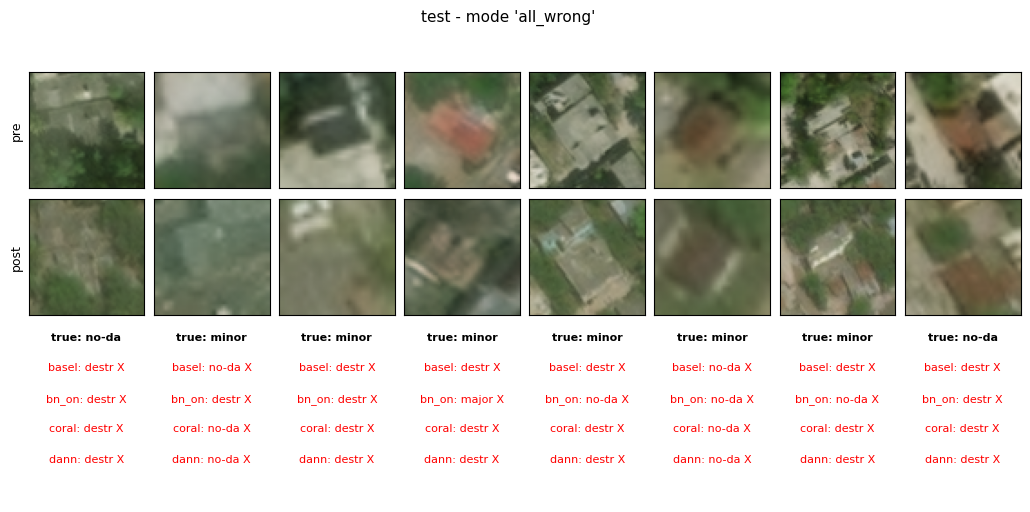

In [14]:
if wide is not None:
    for mode in ("broken", "all_wrong"):
        sel = pick(wide, present, mode=mode)
        if not sel.empty:
            show_cases(sel, present, mode=mode, title=f"{PRED_SPLIT} - mode '{mode}'")

## 13. Whole images: true labels against each method

The crops in section 12 lose the context. Here the same buildings are drawn back onto the
post-disaster tile, one panel for the ground truth and one per method.

- **Box colour = damage class** (green no-damage, yellow minor, orange major, red destroyed).
  The truth panel colours by the real label, the method panels by what that method predicted.
- **Dashed, thicker box = that method got it wrong.** Solid thin = correct.
- Each panel title gives that method's accuracy on this image.

This is the figure for the report: one tile, truth next to baseline next to CORAL, and the
difference is visible without reading any numbers.

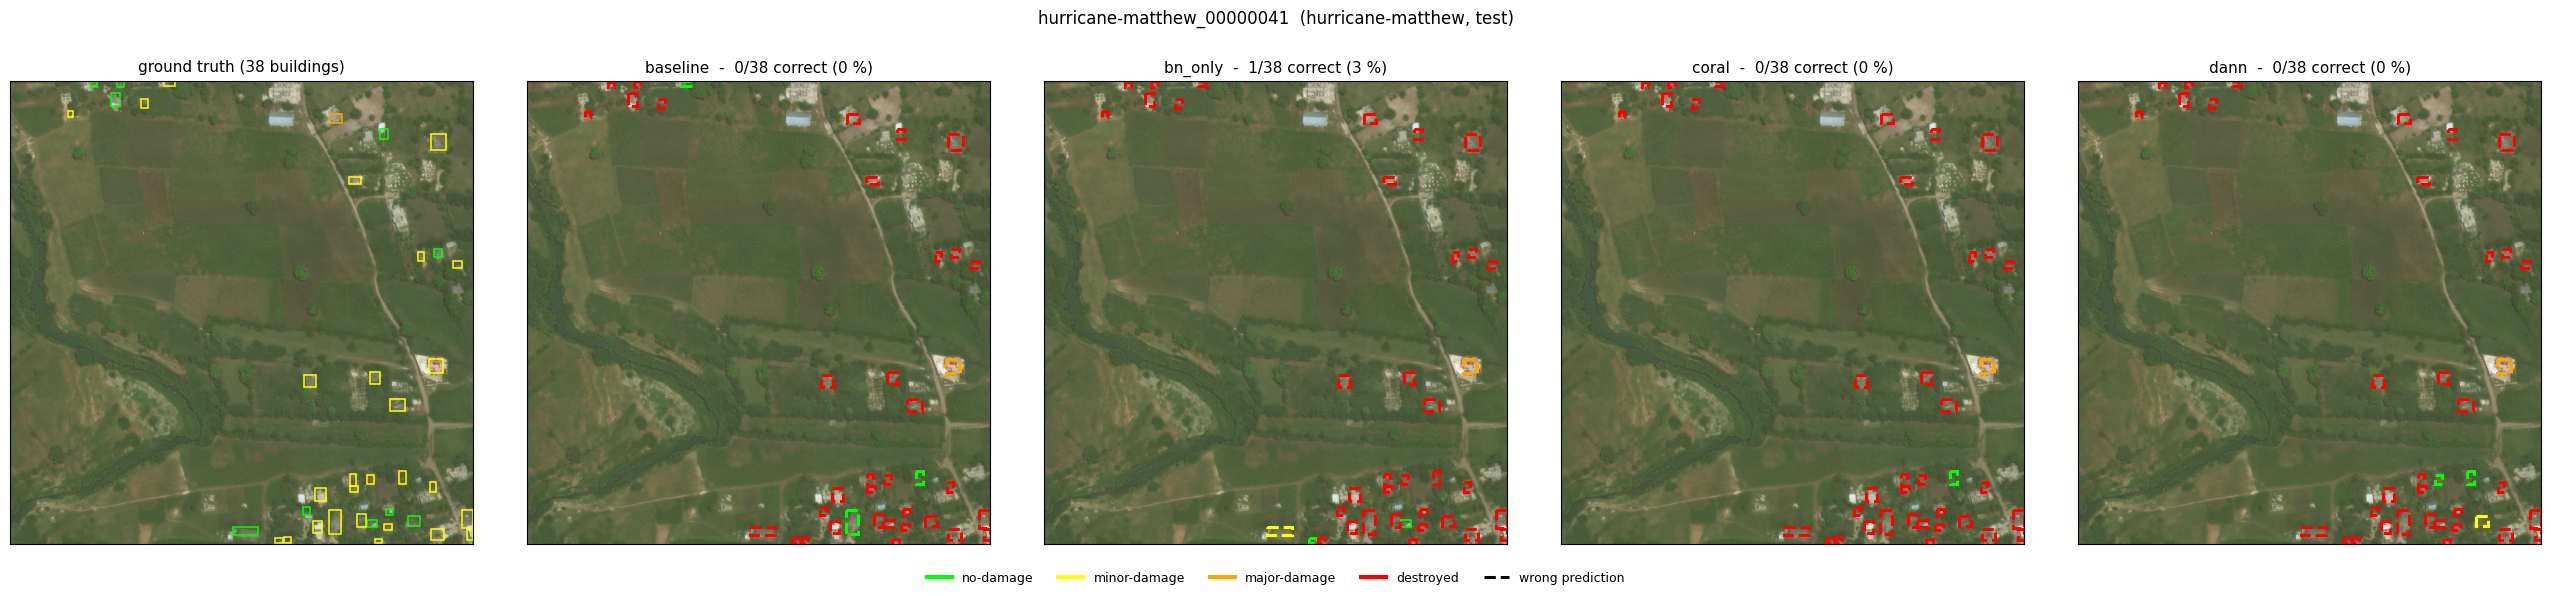

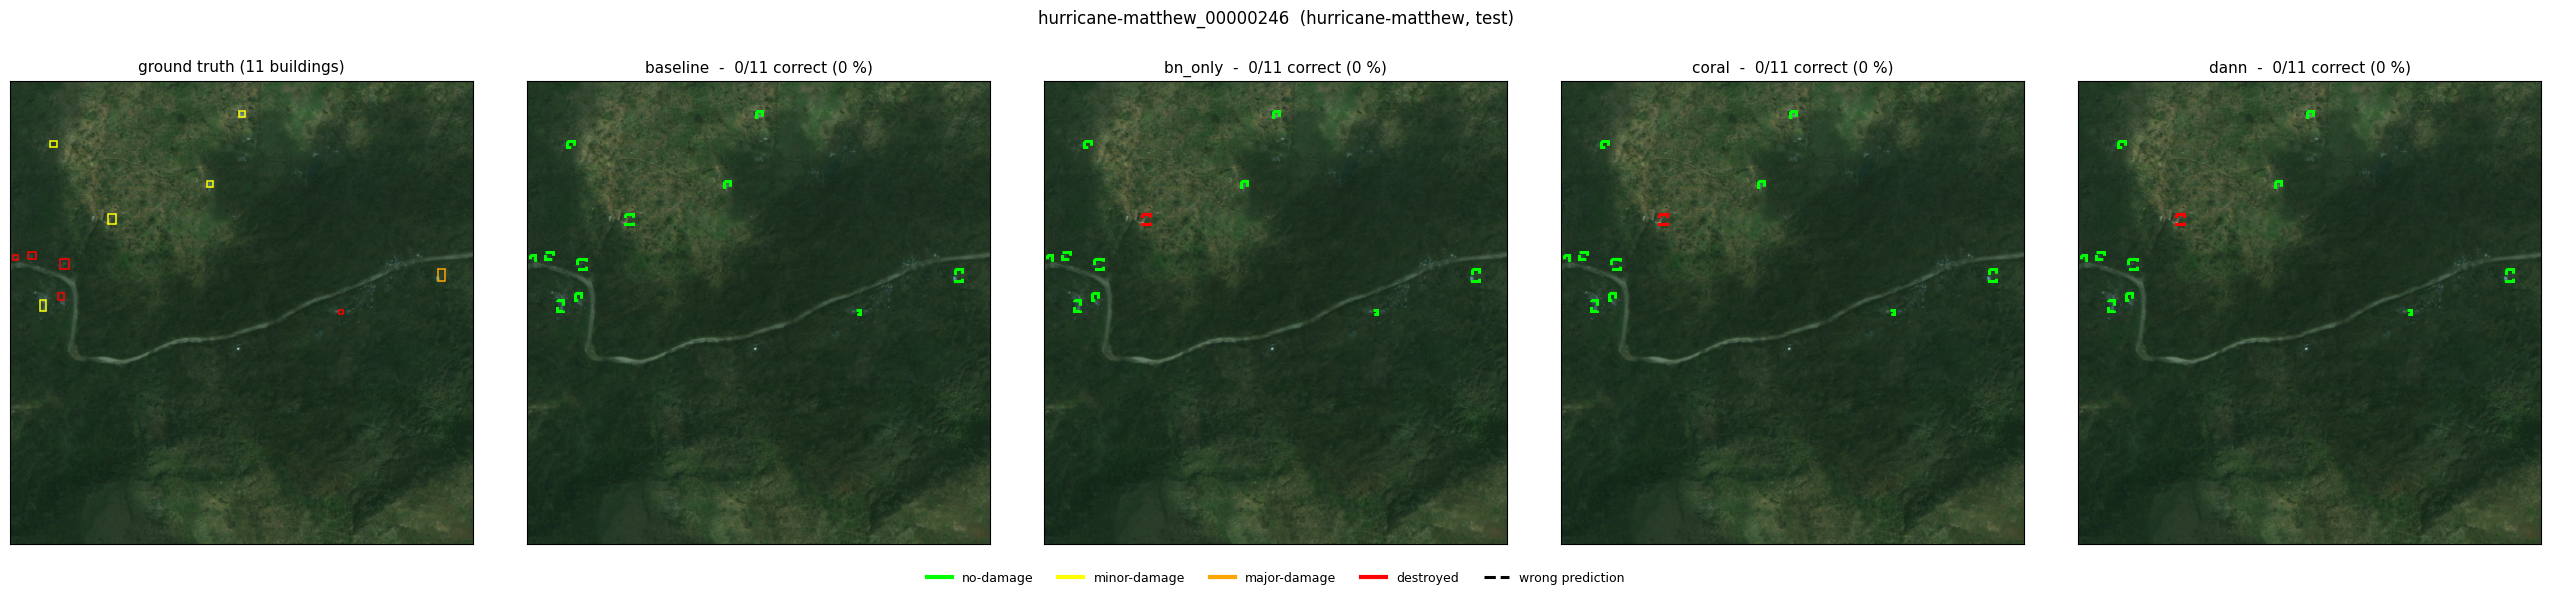

In [15]:
import rasterio
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

SUBSET_DIR = Path("../xbd_subset/wind")        # the full tiles, made by create_subset.py
BOX_COLOR = {0: "lime", 1: "yellow", 2: "orange", 3: "red"}


def read_tile(rel_path):
    with rasterio.open(SUBSET_DIR / rel_path) as src:
        return np.transpose(src.read([1, 2, 3]), (1, 2, 0))


def pick_images(wide, mode="most_errors", n=2, method="baseline", min_buildings=10):
    # which tiles to draw. mode: most_errors | most_disagreement | most_buildings
    df = wide.join(manifest[["image_id", "event"]], how="inner")
    counts = df.groupby("image_id").size()
    keep = counts[counts >= min_buildings].index
    df = df[df["image_id"].isin(keep)]
    if df.empty:
        print(f"no image has at least {min_buildings} buildings in this split")
        return []
    if mode == "most_errors":
        score = df.groupby("image_id").apply(
            lambda g: (g[f"pred_{method}"] != g["true_label"]).mean())
    elif mode == "most_disagreement":
        cols = [f"pred_{m}" for m in present]
        score = df.groupby("image_id").apply(lambda g: g[cols].nunique(axis=1).gt(1).mean())
    else:
        score = counts[keep]
    return list(score.sort_values(ascending=False).head(n).index)


def show_image(image_id, wide, methods, max_panels=5):
    # one tile: ground truth, then one panel per method
    rows = wide.join(manifest[["image_id", "event", "post_path",
                               "x_min", "y_min", "x_max", "y_max"]], how="inner")
    rows = rows[rows["image_id"] == image_id]
    if rows.empty:
        print(f"{image_id}: no predictions for this image")
        return
    tile = read_tile(rows["post_path"].iloc[0])
    panels = ["truth"] + list(methods)[:max_panels - 1]

    fig, axes = plt.subplots(1, len(panels), figsize=(5.2 * len(panels), 5.6), squeeze=False)
    for k, panel in enumerate(panels):
        ax = axes[0][k]
        ax.imshow(tile)
        ax.set_xticks([])
        ax.set_yticks([])
        n_right = 0
        for _, r in rows.iterrows():
            true_c = int(r["true_label"])
            if panel == "truth":
                cls, wrong = true_c, False
            else:
                cls = int(r[f"pred_{panel}"])
                wrong = cls != true_c
                n_right += not wrong
            ax.add_patch(Rectangle(
                (r["x_min"], r["y_min"]), r["x_max"] - r["x_min"], r["y_max"] - r["y_min"],
                fill=False, edgecolor=BOX_COLOR[cls],
                linewidth=2.2 if wrong else 1.1, linestyle="--" if wrong else "-"))
        title = (f"ground truth ({len(rows)} buildings)" if panel == "truth"
                 else f"{panel}  -  {n_right}/{len(rows)} correct "
                      f"({100 * n_right / len(rows):.0f} %)")
        ax.set_title(title, fontsize=11)

    handles = [Line2D([0], [0], color=BOX_COLOR[c], lw=3, label=CLASSES[c]) for c in range(4)]
    handles += [Line2D([0], [0], color="black", lw=2.2, ls="--", label="wrong prediction")]
    fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, fontsize=9)
    fig.suptitle(f"{image_id}  ({rows['event'].iloc[0]}, {PRED_SPLIT})", fontsize=12, y=1.04)
    plt.tight_layout(rect=[0, 0.06, 1, 1])
    save_fig(f"image_{image_id}_{PRED_SPLIT}")
    plt.show()


if wide is not None:
    for img_id in pick_images(wide, mode="most_errors", n=2):
        show_image(img_id, wide, present)

Other views of the same function. `most_disagreement` picks the tiles where the methods differ
most from each other, which is usually where adaptation is doing something.

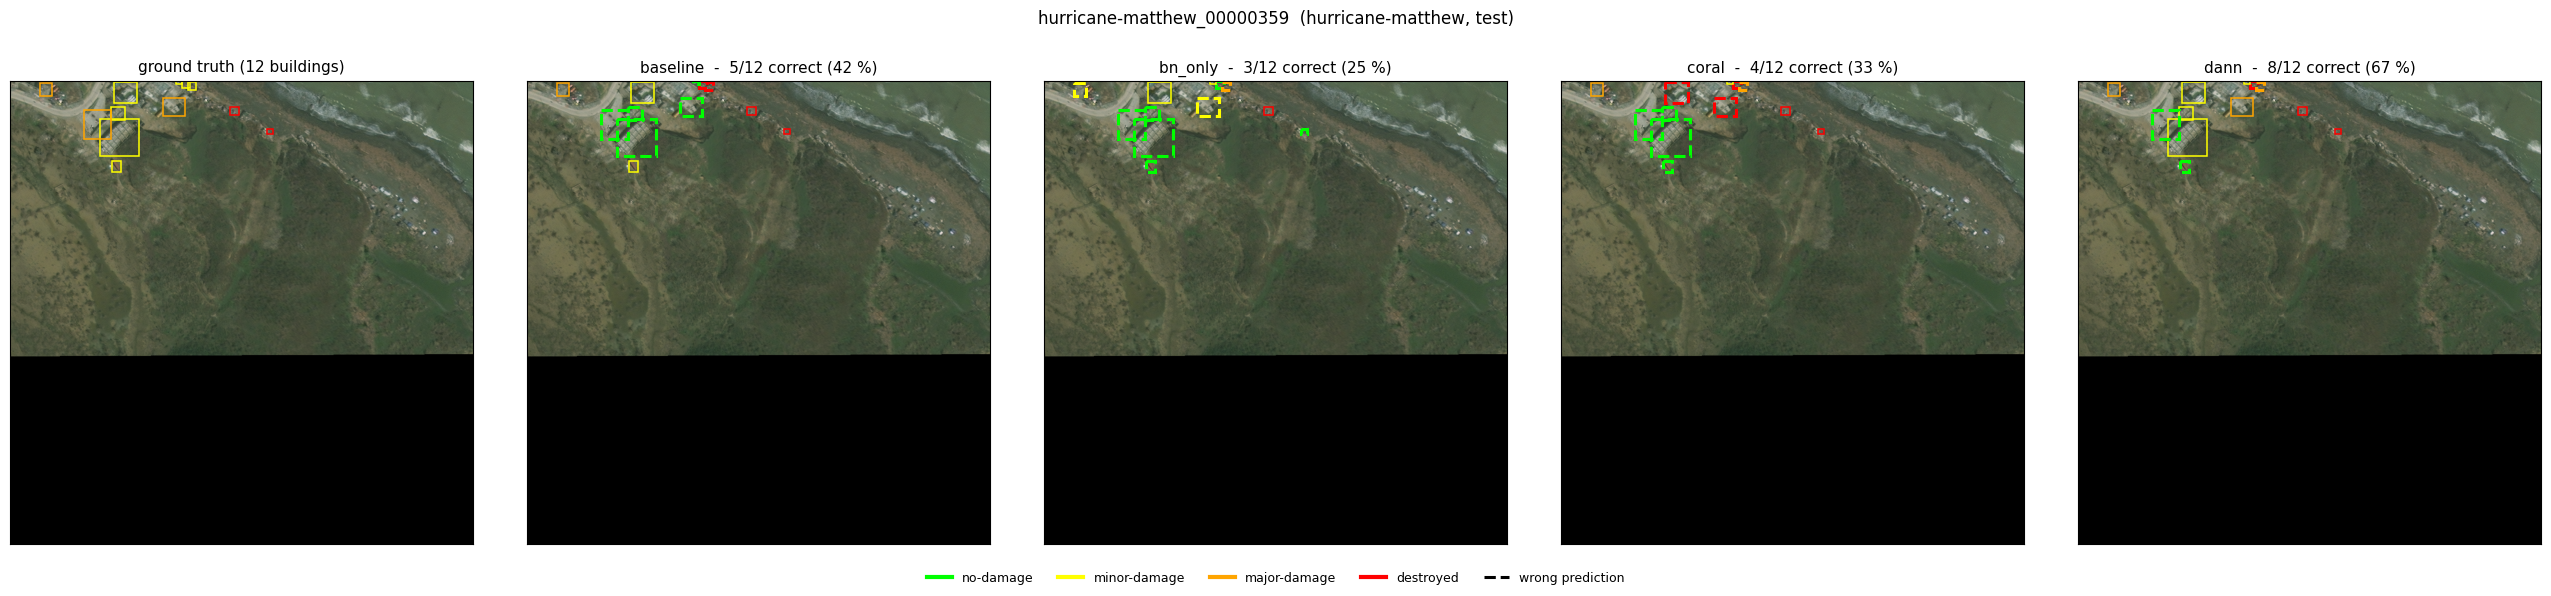

In [16]:
if wide is not None:
    for img_id in pick_images(wide, mode="most_disagreement", n=1):
        show_image(img_id, wide, present)

    # a specific tile:
    #   show_image("hurricane-matthew_00000123", wide, present)
    # every tile available in this split:
    #   sorted(wide.join(manifest[["image_id"]], how="inner")["image_id"].unique())

## 14. Notes

- Figures are saved in `reports/experiments/`, and the raw per-run numbers in
  `all_results_long.csv`.
- Re-run the whole notebook after adding runs; nothing is hard-coded to a particular run.
- `chosen` holds one run per method (best seed on `target_test`). To look at a specific run
  instead: `chosen["dann"] = [r for r in runs if r["name"] == "seed1_2026...."][0]`.
- For image-level figures (buildings drawn on the tile, true versus predicted), join
  `predictions_<split>.csv` to `crops/wind_64/manifest.csv` on `building_uid`.